**Support Vector Machines**

_This notebook contains all the sample code and solutions to the exercises in chapter 5._

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/ageron/handson-ml3/blob/main/05_support_vector_machines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
  <td>
    <a target="_blank" href="https://kaggle.com/kernels/welcome?src=https://github.com/ageron/handson-ml3/blob/main/05_support_vector_machines.ipynb"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" /></a>
  </td>
</table>

# Setup

This project requires Python 3.7 or above:

In [1]:
import sys

assert sys.version_info >= (3, 7)

It also requires Scikit-Learn ≥ 1.0.1:

In [2]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

As we did in previous chapters, let's define the default font sizes to make the figures prettier:

In [3]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

And let's create the `images/svm` folder (if it doesn't already exist), and define the `save_fig()` function which is used through this notebook to save the figures in high-res for the book:

In [4]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "svm"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

# 10.

_Exercise: Train an SVM classifier on the Wine dataset, which you can load using `sklearn.datasets.load_wine()`. This dataset contains the chemical analysis of 178 wine samples produced by 3 different cultivators: the goal is to train a classification model capable of predicting the cultivator based on the wine's chemical analysis. Since SVM classifiers are binary classifiers, you will need to use one-versus-all to classify all 3 classes. What accuracy can you reach?_

First, let's fetch the dataset, look at its description, then split it into a training set and a test set:

In [5]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)

In [6]:
print(wine.DESCR)

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

**Wine Classes and purpose of SVM :**
The Wine dataset contains three classes: Class 0, Class 1, and Class 2. These classes represent wines produced from three different grape cultivars grown in the same region of Italy. Each wine sample contains 13 chemical measurements, including alcohol content, malic acid, magnesium, flavonoids, and color intensity. These measurements help identify differences among the three wine classes.

The purpose of using a Support Vector Machine (SVM) in this exercise is to build a classification model that can predict which class a wine belongs to based on its chemical characteristics. SVM works by finding decision boundaries that separate the classes while maximizing the margin between them. Since the dataset contains three classes, the classifier must distinguish among multiple categories rather than just two. By training the model on known wine samples and evaluating it on unseen test data, we can measure how accurately SVM identifies the correct wine class. This exercise also helps us understand how feature scaling, kernel selection, and hyperparameter tuning affect the model's performance.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    wine.data, wine.target, random_state=42)

In [8]:
X_train.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
100,12.08,2.08,1.70,17.5,97.0,2.23,2.17,0.26,1.40,3.30,1.27,2.96,710.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
154,12.58,1.29,2.10,20.0,103.0,1.48,0.58,0.53,1.40,7.60,0.58,1.55,640.0
51,13.83,1.65,2.60,17.2,94.0,2.45,2.99,0.22,2.29,5.60,1.24,3.37,1265.0


In [9]:
y_train.head()

,target
2,0
100,1
122,1
154,2
51,0


Let's start simple, with a linear SVM classifier. It will automatically use the One-vs-All (also called One-vs-the-Rest, OvR) strategy, so there's nothing special we need to do to handle multiple classes. Easy, right?

In [11]:
from sklearn.svm import LinearSVC
lin_clf = LinearSVC(dual=True, random_state=42)
lin_clf.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC(dual=True, random_state=42)

Oh no! It failed to converge. Can you guess why? Do you think we must just increase the number of training iterations? Let's see:

**Why LinearSVC failed to converge:** The LinearSVC model failed to converge because the features in the Wine dataset have significantly different numerical ranges. For example, alcohol content typically ranges from approximately 11 to 15, while proline values can range from a few hundred to over 1,600. When features are not scaled, those with larger numerical values can have a disproportionate influence on the model's optimization process. This makes it more difficult for LinearSVC to find a stable solution within the default number of training iterations.

Increasing the maximum number of iterations (`max_iter`) might help the model converge, but it does not address the underlying issue of inconsistent feature scales. A more effective approach is to use `StandardScaler`, which standardizes the features to have a mean of approximately zero and a standard deviation of one. This allows the SVM optimization algorithm to work more efficiently and generally improves convergence.

Therefore, the warning highlights the importance of feature preprocessing rather than simply increasing the number of iterations. Proper feature scaling can also improve the model's classification performance and reliability.

In [12]:
lin_clf = LinearSVC(max_iter=1_000_000, dual=True, random_state=42)
lin_clf.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC(dual=True, max_iter=1000000, random_state=42)

Even with one million iterations, it still did not converge. There must be another problem.

Let's still evaluate this model with `cross_val_score`, it will serve as a baseline:

In [13]:
from sklearn.model_selection import cross_val_score

cross_val_score(lin_clf, X_train, y_train).mean()

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


np.float64(0.90997150997151)

Well 91% accuracy on this dataset is not great. So did you guess what the problem is?

That's right, we forgot to scale the features! Always remember to scale the features when using SVMs:

**What is Feature Scaling in SVM:** Feature scaling is a data preprocessing technique used to bring numerical features into a comparable range so that no single feature has an unfair influence on the machine learning model because of its larger numerical values. In the Wine dataset, different chemical measurements have different scales. For example, alcohol content generally ranges from 11 to 15, while proline values can exceed 1,000. Without feature scaling, these differences can affect how the Support Vector Machine (SVM) learns and separates the wine classes.

In this exercise, we use StandardScalar from Scikit-Learn to standardize the features. It transforms each feature by subtracting its mean and dividing by its standard deviation, resulting in features with a mean of approximately zero and a standard deviation of one in the training data. This process preserves the relative differences between observations while making the features more comparable.

Feature scaling is particularly important for SVM because the algorithm relies on distances and margins to determine decision boundaries. When features are properly scaled, the model can optimize more efficiently, converge faster, and potentially achieve better classification accuracy. In this exercise, scaling helps address the limitations observed with the initial unscaled model, which achieved approximately 91% accuracy.

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
lin_clf = make_pipeline(StandardScaler(),
                        LinearSVC(dual=True, random_state=42))
lin_clf.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('linearsvc', LinearSVC(dual=True, random_state=42))])

Now it converges without any problem. Let's measure its performance:

In [16]:
from sklearn.model_selection import cross_val_score

cross_val_score(lin_clf, X_train, y_train).mean()

np.float64(0.9774928774928775)

Nice! We get 97.7% accuracy, that's much better.

Let's see if a kernelized SVM will do better. We will use a default `SVC` for now:

**What is a Kernelized SVM:** A kernelized Support Vector Machine (SVM) is a machine learning classification algorithm that can identify complex, nonlinear relationships between data points. Unlike a linear SVM, which separates classes using straight decision boundaries, a kernelized SVM can create curved or more flexible decision boundaries. This is useful when the data cannot be accurately separated using a simple linear model.

Kernelized SVM uses a technique called the **kernel trick**, which allows the algorithm to calculate similarities between data points as if they were mapped into a higher-dimensional feature space without explicitly performing that transformation. Common kernel functions include linear, polynomial, and Radial Basis Function (RBF) kernels. The RBF kernel is particularly useful because it can capture nonlinear patterns in the data.

In this exercise, we use Scikit-Learn's `SVC` with its default RBF kernel to classify the three wine classes based on their chemical measurements. Before training the model, we apply `StandardScaler` to ensure that features with larger numerical values do not dominate the calculations. The kernelized SVM is then evaluated using cross-validation to determine how accurately it classifies the wine samples.

The purpose of testing a kernelized SVM is to determine whether a nonlinear decision boundary can improve classification performance compared with the linear SVM. However, a more complex model does not always produce better results, so comparing their accuracy helps us understand which approach is more suitable for the Wine dataset.

In [18]:
from sklearn.svm import SVC
svm_clf = make_pipeline(StandardScaler(), SVC(random_state=42))
cross_val_score(svm_clf, X_train, y_train).mean()

np.float64(0.9698005698005698)

That's not better, but perhaps we need to do a bit of hyperparameter tuning:

**What Is Hyperparameter Tuning, and What Hyperparameters Are Being Tuned?** Hyperparameter tuning is the process of finding the best settings for a machine learning model to improve its performance and ability to make accurate predictions on new data. Hyperparameters are values that are selected before training rather than learned directly from the training data. In Support Vector Machines (SVM), choosing appropriate hyperparameters is important because they influence how the model creates decision boundaries, handles classification errors, and captures patterns in the dataset.

In this exercise, we are tuning two hyperparameters of the kernelized SVM: **C and gamma**.

**C (Regularization Parameter):** The C parameter controls the trade-off between allowing classification errors and maintaining a wider decision margin. A higher C value places a greater penalty on classification errors, encouraging the model to classify training samples more accurately, but potentially increasing the risk of overfitting. A lower C value allows more classification errors in exchange for stronger regularization, which may improve generalization.

**Gamma (Kernel Coefficient):** The gamma parameter controls how far the influence of individual training samples extends when using the Radial Basis Function (RBF) kernel. A higher gamma value creates more localized and complex decision boundaries, which can lead to overfitting. A lower gamma value produces smoother decision boundaries, although values that are too low may cause underfitting.

In this exercise, we use RandomizedSearchCV to test 100 randomly selected combinations of C and gamma. The C values are sampled between 1 and 11, while gamma values are sampled between 0.001 and 0.1. The model uses five-fold cross-validation to evaluate these combinations and identify the settings that achieve the highest average validation accuracy.

The purpose of hyperparameter tuning is to find a balance between model complexity and classification accuracy. By selecting appropriate values for C and gamma, we aim to improve the SVM's ability to correctly classify the three wine classes while reducing the risk of overfitting.

In [19]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, uniform

param_distrib = {
    "svc__gamma": loguniform(0.001, 0.1),
    "svc__C": uniform(1, 10)
}
rnd_search_cv = RandomizedSearchCV(svm_clf, param_distrib, n_iter=100, cv=5,
                                   random_state=42)
rnd_search_cv.fit(X_train, y_train)
rnd_search_cv.best_estimator_

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc',
                 SVC(C=np.float64(9.925589984899778),
                     gamma=np.float64(0.011986281799901188),
                     random_state=42))])

In [20]:
rnd_search_cv.best_score_

np.float64(0.9925925925925926)

Ah, this looks excellent! Let's select this model. Now we can test it on the test set:

In [21]:
rnd_search_cv.score(X_test, y_test)

0.9777777777777777

**Interpretation of SVM Test Accuracy:**
The rnd_search_cv.score(X_test, y_test) statement evaluates the performance of the Support Vector Machine (SVM) model after hyperparameter tuning. The model achieved a test accuracy of **0.9777, or approximately 97.78%**, which indicates that it correctly classified 97.78% of the wine samples in the test dataset.

In this exercise, RandomizedSearchCV was used to identify suitable values for the C and gamma hyperparameters through cross-validation. After selecting the best combination, the optimized SVM model was evaluated using test data that had not been used during training or hyperparameter tuning. The accuracy of 97.78% means that the model correctly predicted 44 out of 45 wine samples, with only one incorrect classification.

This result demonstrates that the SVM model can effectively distinguish among the three wine classes based on their chemical characteristics. The high accuracy suggests that feature scaling and hyperparameter tuning helped the model learn useful classification patterns and generalize well to unseen data. However, accuracy alone does not identify which wine class was misclassified or explain why the incorrect prediction occurred.

Overall, the 97.78% test accuracy indicates strong classification performance. Comparing the actual and predicted wine classes through a visualization or confusion matrix would provide additional insight into the model's predictions and help identify areas where classification errors occur.

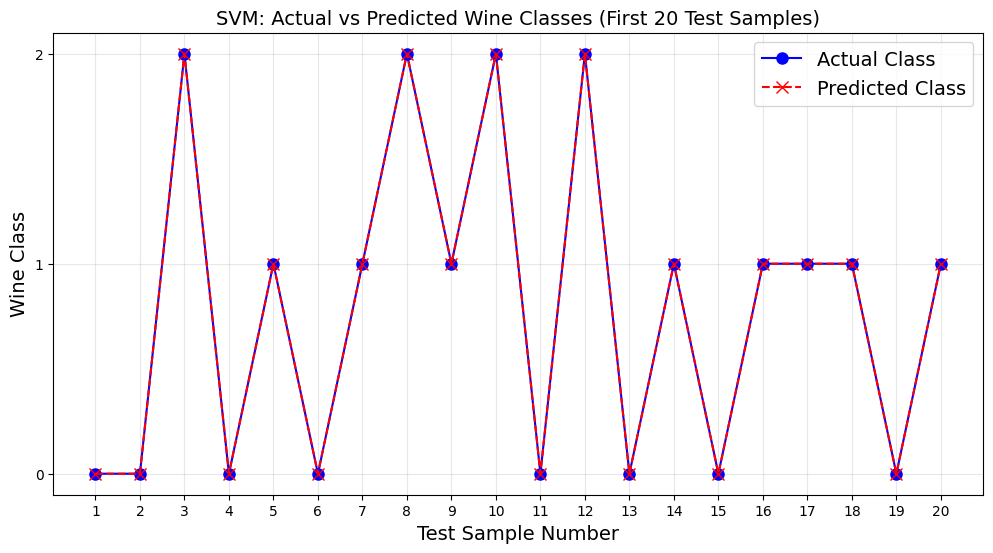

In [22]:
# Actual vs. Predicted Wine Classes (First 20 Test Samples)
import matplotlib.pyplot as plt
import numpy as np

# Select the first 20 samples from the test dataset
X_test_20 = X_test[:20]
y_actual = y_test[:20]

# Predict wine classes using the tuned SVM model
y_predicted = rnd_search_cv.predict(X_test_20)

# Create a visualization
plt.figure(figsize=(12, 6))

sample_numbers = np.arange(1, 21)

plt.plot(sample_numbers, y_actual, 'bo-',
         label='Actual Class', markersize=8)

plt.plot(sample_numbers, y_predicted, 'rx--',
         label='Predicted Class', markersize=8)

plt.xlabel('Test Sample Number')
plt.ylabel('Wine Class')
plt.title('SVM: Actual vs Predicted Wine Classes (First 20 Test Samples)')

plt.xticks(sample_numbers)
plt.yticks([0, 1, 2])
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

This tuned kernelized SVM performs better than the `LinearSVC` model, but we get a lower score on the test set than we measured using cross-validation. This is quite common: since we did so much hyperparameter tuning, we ended up slightly overfitting the cross-validation test sets. It's tempting to tweak the hyperparameters a bit more until we get a better result on the test set, but this would probably not help, as we would just start overfitting the test set. Anyway, this score is not bad at all, so let's stop here.

**Reflection: **

**1. Give two real-world business or technology applications where SVM can be used.**

Support Vector Machines (SVM) are widely used in business and technology because they can identify patterns and classify data based on different characteristics. Two practical applications are fraud detection in financial services and medical diagnosis in healthcare.

**Fraud Detection in Banking:** Financial institutions can use SVM to identify potentially fraudulent transactions by analyzing information such as transaction amounts, purchase locations, transaction frequency, and customer spending patterns. The model can learn differences between legitimate and suspicious transactions and classify new transactions accordingly. This helps financial institutions identify unusual activities and reduce financial risks. However, suspicious transactions generally require further investigation because a model's prediction does not automatically confirm fraud.

**Medical Diagnosis in Healthcare:** SVM can also support medical diagnosis by analyzing patient information, laboratory results, and medical measurements. For example, an SVM model can help classify tumors as benign or malignant based on measurable characteristics. By learning patterns from previously labeled medical data, the model can assist healthcare professionals in identifying possible health conditions. However, these predictions should support clinical decisions rather than replace professional medical judgment.

Both applications demonstrate how SVM can transform historical data into useful predictions that support decision-making.

**2. What is the difference between LinearSVC and kernelized SVM?**

The main difference between LinearSVC and kernelized SVM is how they create decision boundaries to separate different classes of data.

LinearSVC uses a linear decision boundary, meaning it attempts to separate classes using a straight line in two dimensions or a hyperplane in higher dimensions. It is generally computationally efficient and works well when the relationship between features and classes is approximately linear. However, it may struggle when the data contains complex nonlinear patterns.

A kernelized SVM, such as Scikit-Learn's SVC with the Radial Basis Function (RBF) kernel, can identify nonlinear relationships. It uses the kernel trick to calculate similarities between observations in a higher-dimensional feature space without explicitly transforming all the data into that space. This allows the model to create more flexible decision boundaries.

In the Wine dataset exercise, we initially used LinearSVC and observed convergence difficulties when the features were not scaled. After applying StandardScaler, the model could train more effectively. We then tested a kernelized SVM and tuned its C and gamma hyperparameters using RandomizedSearchCV. The optimized model achieved a test accuracy of 97.78%. This exercise demonstrated that feature scaling, model selection, and hyperparameter tuning can influence classification performance.

**3. Why would you want to visualize the predicted versus actual results at the end of the program?**

Visualizing predicted versus actual results is important because it allows us to evaluate the model's performance beyond a single accuracy score. Although accuracy tells us the percentage of correct predictions, it does not show which individual samples were classified correctly or incorrectly.

In this exercise, the optimized SVM achieved a test accuracy of 97.78%, correctly classifying 44 out of 45 wine samples. By comparing the actual and predicted classes for the first 20 test samples, we can visually identify where the predictions match and where any differences occur. Matching values indicate correct classifications, while differences represent classification errors.

This visualization also helps us understand how the model performs across the three wine classes. If misclassifications occur, we can investigate whether the model has difficulty distinguishing particular classes. However, the first 20 samples represent only part of the test dataset, so the visualization should be interpreted alongside the overall accuracy and other evaluation methods.

Overall, visualizing predictions makes the model's results easier to interpret, helps identify possible classification problems, and provides additional evidence when evaluating the reliability of the SVM model.

**4. Write a statement explaining how you used AI in this assignment.**

I used AI assistance, to support my understanding of Support Vector Machines and complete the programming exercises in Google Colab. AI helped me understand the differences between LinearSVC and kernelized SVM, the importance of feature scaling, and how the C and gamma hyperparameters influence model performance.

I also used AI to help troubleshoot Python errors, particularly missing imports for Scikit-Learn functions such as LinearSVC, SVC, and make_pipeline. AI assistance helped me understand the convergence warning and how StandardScaler can improve the training process.

I reviewed the explanations and used the notebook's execution results to understand how the different steps contributed to the final classification performance. AI served as a learning and troubleshooting resource rather than a replacement for understanding the concepts and interpreting the results independently.